# Parcial 2 - Ejercicio 1: Clasificación de imágenes por parches (aprendizaje no supervisado + clasificación)

**Objetivo:** construir un programa que ponga **etiquetas** al objeto principal que aparece en pequeñas imágenes de **64 x 64 píxeles** obtenidas al dividir fotos reales de quebradas con basura, y luego entrenar un **modelo que clasifique** esas imágenes.

**Datos usados**

| Dataset | Carpeta original | Uso |
|---|---|---|
| ds1 (carpeta de *erick_alexander_ochoa_paz*, 30 fotos) | `_descargas/ds1/erick_alexander_ochoa_paz` | Entrenamiento y prueba |
| ds2 (8 fotos) | `_descargas/ds2` | Imágenes nuevas para probar el modelo ya entrenado |

Elegí la carpeta de ds1 que tenía **más fotos** (30) y todas en formato JPG. Las fotos originales pesan varios MB y miden hasta 4096 px, así que lo primero es **reducirlas**.

## Cómo lo hice (resumen de la estrategia)

1. **Reducir** cada foto para que su lado más largo mida 512 px (se conserva la proporción).
2. **Dividir** cada foto en parches de **64 x 64** (una foto vertical de 384 x 512 da 6 x 8 = 48 parches).
3. **Describir** cada parche con **51 números** de color y textura (histogramas de color, medias, desviaciones, bordes).
4. **Separar** fotos completas para prueba (7 fotos) y entrenamiento (23 fotos), para no hacer trampa.
5. **Aprendizaje no supervisado:** aplicar **K-Means con k = 50** a los parches de entrenamiento. Cada grupo junta parches parecidos.
6. **Etiquetar solo 50 parches** (el más representativo de cada grupo, el más cercano al centroide) con una de 5 etiquetas: `basura`, `vegetacion`, `tierra`, `cielo`, `construccion`.
7. **Propagar** la etiqueta de cada representativo a todo su grupo (aprendizaje semi-supervisado, igual que en el cuadernillo de clase de aprendizaje no supervisado).
8. **Entrenar una regresión logística** (vista en clase, *one vs all* / multiclase) con esas etiquetas.
9. **Medir** el modelo contra parches de prueba que etiqueté a mano: exactitud, precisión, *recall*, F1, matriz de confusión y validación cruzada.
10. **Usar el modelo** sobre las fotos nuevas de ds2 y guardar el modelo entrenado.

## 1. Librerías

Uso solo librerías vistas en clase: `numpy`, `pandas`, `matplotlib`, `PIL` para leer imágenes y `scikit-learn` para K-Means, regresión logística y métricas.

In [1]:
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_score
from sklearn.metrics import (silhouette_score, accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Las figuras se guardan en JPEG para que el cuadernillo no pese demasiado
%config InlineBackend.figure_format = 'jpeg'

# Semilla fija para que todo el cuadernillo sea reproducible
SEMILLA = 42
np.random.seed(SEMILLA)

## 2. Reducción del dataset

Las fotos originales son grandes (hasta 4096 x 3072 px). Para trabajar con parches de 64 x 64 no necesito tanta resolución: si dejara la foto original, un parche de 64 px mostraría un pedacito minúsculo (una hoja, una piedra) y no el **objeto principal**. Al reducir el lado mayor a **512 px**, cada parche cubre más o menos 1/8 del ancho de la foto, que es suficiente para ver si ahí hay basura, plantas, tierra o cielo.

Además:
- `ImageOps.exif_transpose` gira la foto según la orientación con que se tomó en el celular.
- Las fotos se renombran como `img_00.jpg`, `img_01.jpg`, ... para que los nombres sean cortos.
- Si la carpeta original no existe (por ejemplo en el repositorio, donde solo subo las reducidas), se usan directamente las imágenes ya reducidas.

In [2]:
RUTA_ORIGINAL_DS1 = '_descargas/ds1/erick_alexander_ochoa_paz'
RUTA_ORIGINAL_DS2 = '_descargas/ds2'
RUTA_DS1 = 'datos/ds1_reducido'
RUTA_DS2 = 'datos/ds2_reducido'
LADO_MAXIMO = 512


def tamano_carpeta_mb(carpeta):
    # Suma el peso de todos los archivos de la carpeta, en megabytes
    return sum(os.path.getsize(os.path.join(carpeta, f)) for f in os.listdir(carpeta)) / 1e6


def reducir_dataset(origen, destino, lado_maximo=LADO_MAXIMO):
    if not os.path.isdir(origen):
        print(f'No existe {origen}: se usan las imágenes ya reducidas de {destino}')
        return
    os.makedirs(destino, exist_ok=True)
    archivos = sorted(f for f in os.listdir(origen) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    for i, nombre in enumerate(archivos):
        imagen = Image.open(os.path.join(origen, nombre))
        imagen = ImageOps.exif_transpose(imagen).convert('RGB')
        # thumbnail reduce la imagen manteniendo la proporción: el lado mayor queda en 512 px
        imagen.thumbnail((lado_maximo, lado_maximo), Image.LANCZOS)
        imagen.save(os.path.join(destino, f'img_{i:02d}.jpg'), quality=90)
    print(f'{len(archivos)} fotos: {tamano_carpeta_mb(origen):.1f} MB -> {tamano_carpeta_mb(destino):.1f} MB')


reducir_dataset(RUTA_ORIGINAL_DS1, RUTA_DS1)
reducir_dataset(RUTA_ORIGINAL_DS2, RUTA_DS2)

30 fotos: 17.8 MB -> 3.0 MB


8 fotos: 87.5 MB -> 0.9 MB


In [3]:
nombres_ds1 = sorted(os.listdir(RUTA_DS1))
imagenes_ds1 = {n: np.asarray(Image.open(os.path.join(RUTA_DS1, n)).convert('RGB')) for n in nombres_ds1}

print('Fotos de ds1:', len(imagenes_ds1))
pd.Series({n: im.shape for n, im in imagenes_ds1.items()}).value_counts()

Fotos de ds1: 30


(512, 384, 3)    8
(288, 512, 3)    5
(512, 292, 3)    4
(512, 290, 3)    3
(384, 512, 3)    2
(512, 297, 3)    1
(512, 291, 3)    1
(386, 512, 3)    1
(512, 299, 3)    1
(512, 410, 3)    1
(512, 412, 3)    1
(512, 413, 3)    1
(512, 417, 3)    1
Name: count, dtype: int64

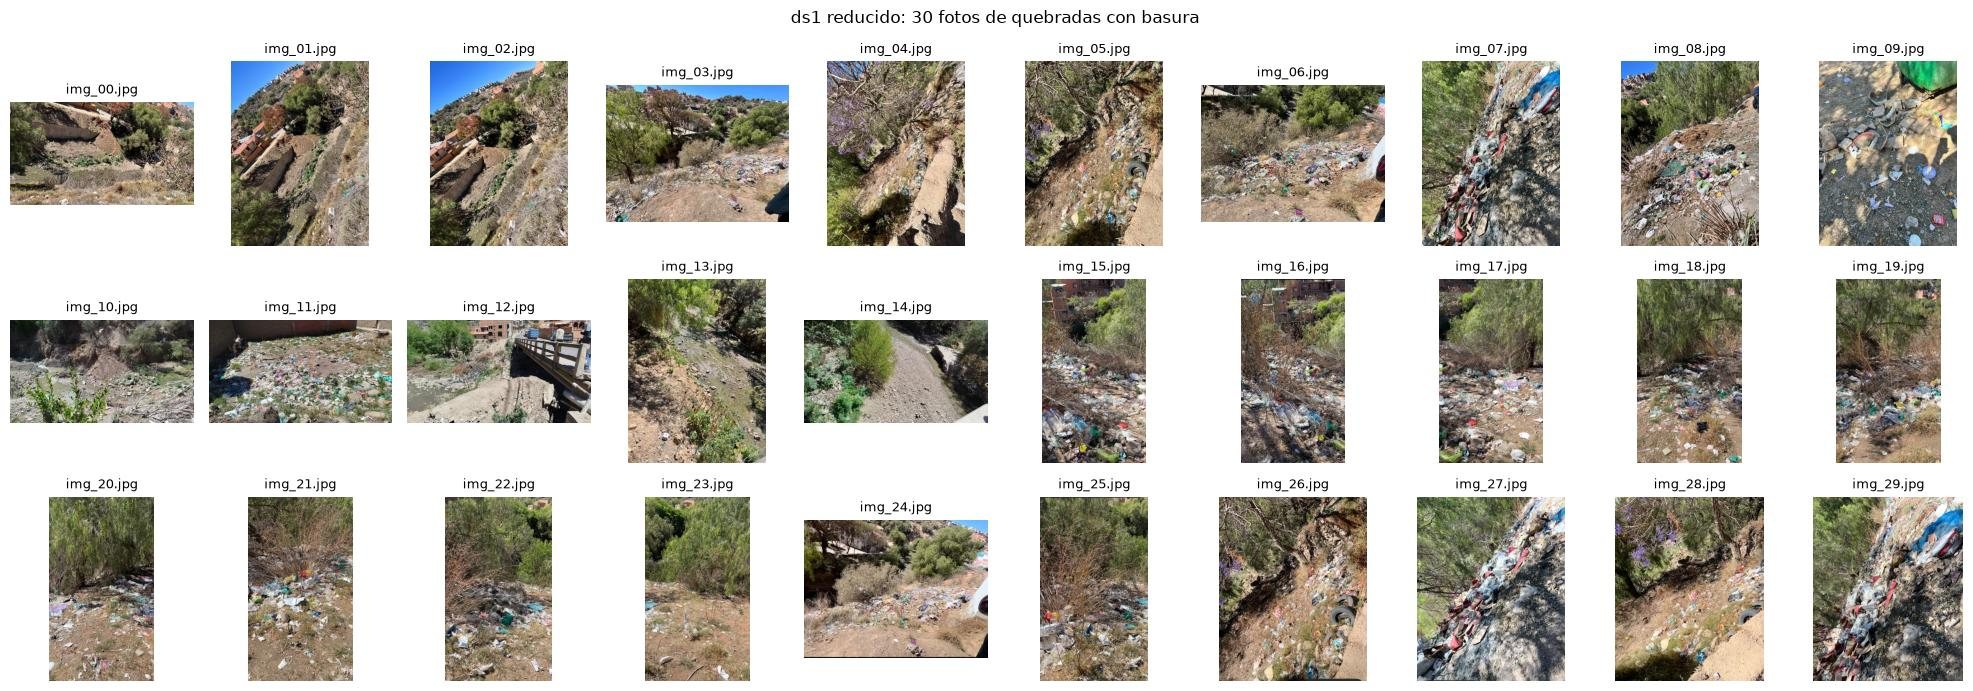

In [4]:
fig, axs = plt.subplots(3, 10, figsize=(20, 7))
for ax, (nombre, imagen) in zip(axs.ravel(), imagenes_ds1.items()):
    ax.imshow(imagen)
    ax.set_title(nombre, fontsize=9)
    ax.axis('off')
plt.suptitle('ds1 reducido: 30 fotos de quebradas con basura')
plt.tight_layout()
plt.show()

## 3. Dividir cada foto en imágenes más pequeñas (parches de 64 x 64)

Cada foto se recorre como una cuadrícula: fila por fila y columna por columna se recorta un cuadrado de 64 x 64. Lo que sobra en el borde (si el tamaño no es múltiplo de 64) se descarta. Para cada parche guardo **de qué foto viene, su fila y su columna**, porque luego necesito:
- separar entrenamiento y prueba **por foto**, y
- volver a dibujar las etiquetas encima de la foto original.

¿Por qué 64 x 64 y no 128 x 128? Con 128 casi todos los parches mezclarían basura, plantas y tierra al mismo tiempo; con 64 la mayoría de los parches tiene un objeto que domina, y además obtengo 4 veces más ejemplos (1200 en vez de ~300), lo cual ayuda con un dataset de solo 30 fotos.

In [5]:
TAM_PARCHE = 64


def dividir_en_parches(imagen, tam=TAM_PARCHE):
    alto, ancho = imagen.shape[:2]
    parches, posiciones = [], []
    for fila in range(alto // tam):
        for col in range(ancho // tam):
            parches.append(imagen[fila * tam:(fila + 1) * tam, col * tam:(col + 1) * tam])
            posiciones.append((fila, col))
    return parches, posiciones


parches, info = [], []
for nombre, imagen in imagenes_ds1.items():
    ps, pos = dividir_en_parches(imagen)
    parches += ps
    info += [(nombre, fila, col) for fila, col in pos]

parches = np.array(parches)
info = pd.DataFrame(info, columns=['imagen', 'fila', 'columna'])

print('Forma del arreglo de parches:', parches.shape)
info.head()

Forma del arreglo de parches: (1200, 64, 64, 3)


,imagen,fila,columna
0,img_00.jpg,0,0
1,img_00.jpg,0,1
2,img_00.jpg,0,2
3,img_00.jpg,0,3
4,img_00.jpg,0,4


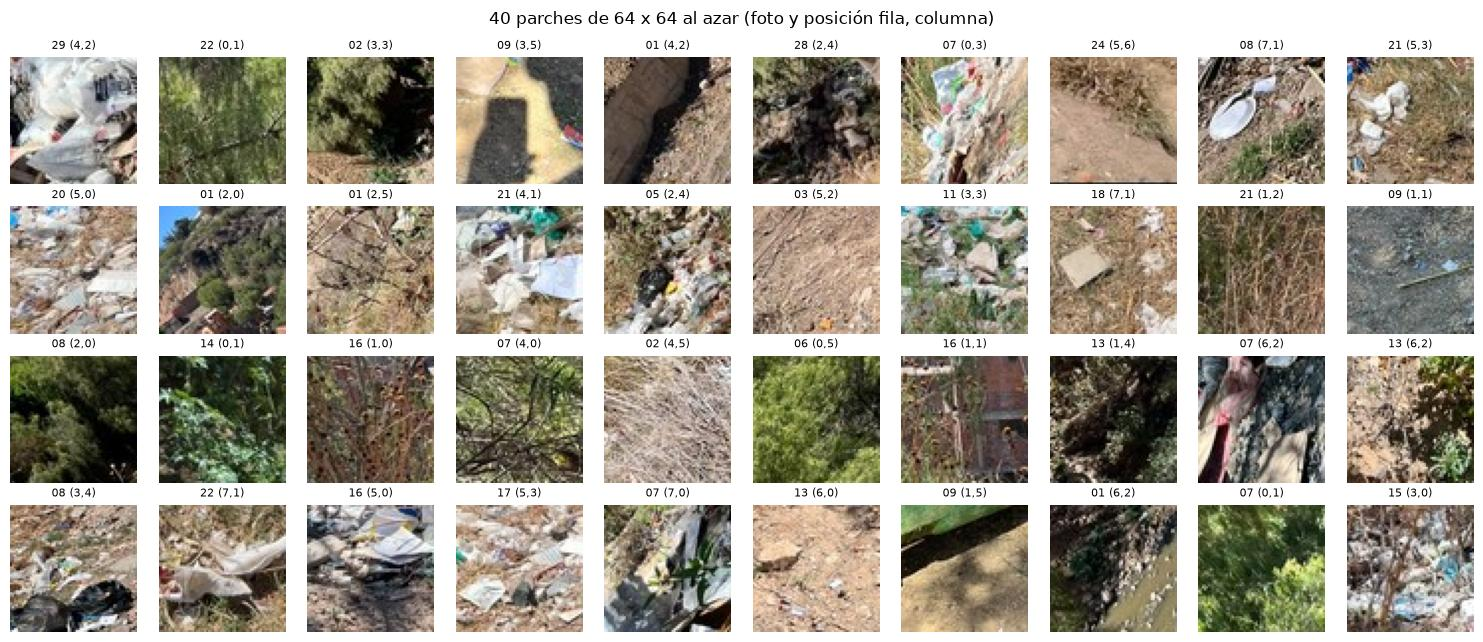

In [6]:
indices = np.random.choice(len(parches), 40, replace=False)
fig, axs = plt.subplots(4, 10, figsize=(15, 6.5))
for ax, i in zip(axs.ravel(), indices):
    ax.imshow(parches[i])
    ax.set_title(f"{info.imagen[i][4:6]} ({info.fila[i]},{info.columna[i]})", fontsize=8)
    ax.axis('off')
plt.suptitle('40 parches de 64 x 64 al azar (foto y posición fila, columna)')
plt.tight_layout()
plt.show()

## 4. Características de cada parche (de 12 288 píxeles a 51 números)

Un parche tiene 64 x 64 x 3 = 12 288 valores. Primero probé K-Means directamente con los píxeles (como se hace con MNIST en clase), pero los grupos salían mezclados: K-Means agrupaba por **brillo y posición** (por ejemplo "parches oscuros arriba a la izquierda") y no por **contenido**. En MNIST funciona porque los dígitos están centrados; en fotos reales la basura puede estar en cualquier parte del parche.

Por eso describo cada parche con números que **no dependen de dónde** están las cosas dentro del parche:

| Grupo | Cantidad | Qué captura |
|---|---|---|
| Histograma de rojo, verde y azul (8 intervalos cada uno) | 24 | La distribución de colores. El cielo es casi todo azul, la tierra es marrón |
| Histograma del **tono** (HSV) pesado por la saturación | 12 | Qué colores "vivos" hay: verde de plantas, plásticos rojos/azules/celestes |
| Histograma de la **saturación** | 6 | Si los colores son intensos (basura plástica) o apagados (tierra, concreto) |
| Media y desviación de R, G, B | 6 | Color promedio y cuánto varía |
| Bordes horizontales, verticales y desviación del gris | 3 | La **textura**: el cielo es liso, la basura y las ramas tienen muchos bordes |

Total: **51 características**. Luego se **estandarizan** (media 0, desviación 1) para que ninguna domine a las demás en las distancias de K-Means y en la regresión logística.

In [7]:
def caracteristicas(parche):
    rgb = parche.astype(float) / 255.0
    hsv = np.asarray(Image.fromarray(parche).convert('HSV')).astype(float) / 255.0
    gris = rgb.mean(axis=2)
    n = gris.size
    vector = []
    # 24: histograma de cada canal R, G, B (proporción de píxeles en cada intervalo)
    for canal in range(3):
        vector += list(np.histogram(rgb[:, :, canal], bins=8, range=(0, 1))[0] / n)
    # 12: histograma del tono, cada píxel pesa según su saturación (los grises casi no cuentan)
    vector += list(np.histogram(hsv[:, :, 0], bins=12, range=(0, 1), weights=hsv[:, :, 1])[0] / n)
    # 6: histograma de la saturación
    vector += list(np.histogram(hsv[:, :, 1], bins=6, range=(0, 1))[0] / n)
    # 6: color promedio y variación de cada canal
    vector += [rgb[:, :, c].mean() for c in range(3)] + [rgb[:, :, c].std() for c in range(3)]
    # 3: textura = cambio promedio entre píxeles vecinos (bordes) y contraste
    vector += [np.abs(np.diff(gris, axis=1)).mean(), np.abs(np.diff(gris, axis=0)).mean(), gris.std()]
    return vector


X = np.array([caracteristicas(p) for p in parches])
print('Matriz de características X:', X.shape)

Matriz de características X: (1200, 51)


## 5. Separar entrenamiento y prueba **por foto** (buena práctica clave)

Si mezclara los parches de todas las fotos y luego los separara al azar, parches vecinos de **la misma foto** (misma luz, mismo lugar, misma cámara) quedarían unos en entrenamiento y otros en prueba. El modelo parecería muy bueno, pero sería **fuga de información** (*data leakage*): estaría "reconociendo la foto" y no aprendiendo qué es basura.

Por eso separo **fotos completas**:
- `train_test_split` con 20% para prueba y semilla 42 eligió 6 fotos.
- Agregué `img_03.jpg` a prueba porque es la única con cielo y construcciones bien visibles; sin ella no podría medir esas clases.

Las 7 fotos de prueba **no se usan en nada** del entrenamiento: ni para el escalado, ni para K-Means, ni para la regresión logística.

In [8]:
_, prueba_azar = train_test_split(nombres_ds1, test_size=0.2, random_state=SEMILLA)
IMAGENES_PRUEBA = sorted(set(prueba_azar) | {'img_03.jpg'})
IMAGENES_ENTRENAMIENTO = [n for n in nombres_ds1 if n not in IMAGENES_PRUEBA]

es_prueba = info.imagen.isin(IMAGENES_PRUEBA).values
X_train, X_test = X[~es_prueba], X[es_prueba]
parches_train, parches_test = parches[~es_prueba], parches[es_prueba]
info_train, info_test = info[~es_prueba].reset_index(drop=True), info[es_prueba].reset_index(drop=True)

print('Fotos de prueba:', IMAGENES_PRUEBA)
print(f'Entrenamiento: {len(IMAGENES_ENTRENAMIENTO)} fotos, {len(X_train)} parches')
print(f'Prueba:        {len(IMAGENES_PRUEBA)} fotos, {len(X_test)} parches')

Fotos de prueba: ['img_03.jpg', 'img_08.jpg', 'img_09.jpg', 'img_15.jpg', 'img_17.jpg', 'img_23.jpg', 'img_27.jpg']
Entrenamiento: 23 fotos, 912 parches
Prueba:        7 fotos, 288 parches


## 6. Aprendizaje no supervisado: K-Means sobre los parches de entrenamiento

Aquí todavía **no hay etiquetas**. K-Means agrupa los parches que tienen características parecidas.

Primero estandarizo con `StandardScaler` (ajustado **solo con entrenamiento**). Luego reviso la **inercia** (suma de distancias al centroide, el "codo") y el **coeficiente de silueta** para distintos valores de k.

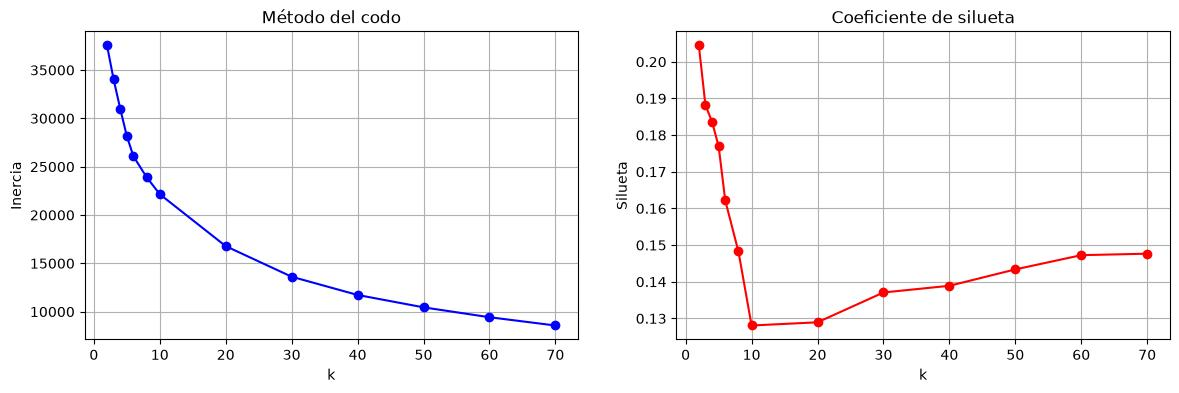

,0,1,2,3,4,5,6,7,8,9,10,11,12
k,2.000,3.000,4.000,5.000,6.000,8.000,10.000,20.000,30.000,40.000,50.000,60.000,70.000
inercia,37539.000,34023.000,31005.000,28169.000,26079.000,23917.000,22153.000,16779.000,13616.000,11728.000,10448.000,9425.000,8569.000
silueta,0.204,0.188,0.184,0.177,0.162,0.148,0.128,0.129,0.137,0.139,0.143,0.147,0.148


In [9]:
escalador = StandardScaler().fit(X_train)
X_train_esc = escalador.transform(X_train)

valores_k = [2, 3, 4, 5, 6, 8, 10, 20, 30, 40, 50, 60, 70]
inercias, siluetas = [], []
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X_train_esc)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_train_esc, km.labels_))

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(valores_k, inercias, 'bo-')
axs[0].set_xlabel('k')
axs[0].set_ylabel('Inercia')
axs[0].set_title('Método del codo')
axs[1].plot(valores_k, siluetas, 'ro-')
axs[1].set_xlabel('k')
axs[1].set_ylabel('Silueta')
axs[1].set_title('Coeficiente de silueta')
for ax in axs:
    ax.grid(True)
plt.show()

pd.DataFrame({'k': valores_k, 'inercia': np.round(inercias, 0), 'silueta': np.round(siluetas, 3)}).T

**Cómo leo estas gráficas:** no hay un codo claro y la silueta es baja para todos los k (entre 0.13 y 0.20) y baja todavía más al aumentar k. Esto es normal en fotos reales: los parches **no forman grupos perfectamente separados** (un parche puede tener un poco de tierra y un poco de basura). Es muy distinto del ejemplo de clase con *blobs* sintéticos.

Por eso no busco "el k verdadero". Hago lo mismo que en el cuadernillo de clase con los dígitos: uso **k = 50**, muchos más grupos que clases. Con 50 grupos cada grupo es pequeño y **más puro** (casi todos sus parches son de la misma clase), y así basta con etiquetar a mano **un parche por grupo**.

In [10]:
K = 50
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X_train_esc)

# distancia de cada parche a cada uno de los 50 centroides
distancias = kmeans.transform(X_train_esc)
# parche representativo = el más cercano a cada centroide
idx_representativos = np.argmin(distancias, axis=0)

print('Parches por grupo:', np.bincount(kmeans.labels_))

Parches por grupo: [33 23 27 21 40 26 42 27  2 20 59  4  8  5 37  8  3  3 33 16 26 19  5  4
  4  7  4 34 22  8  1 16  4  3 16 12 31  7 57  1  4 23 11  5 32 24 11 17
 13 54]


## 7. Etiquetado manual de los 50 parches representativos

Estas son las **5 etiquetas** (el "tipo de imagen" según el objeto principal):

| Etiqueta | Criterio que usé al etiquetar |
|---|---|
| `basura` | Plásticos, bolsas, papeles, escombros o desechos ocupan una parte importante del parche |
| `vegetacion` | Árboles, arbustos, pasto o ramas secas dominan el parche |
| `tierra` | Suelo, piedras o arena; puede tener algún desecho pequeño, pero no domina |
| `cielo` | Cielo (a veces con el borde de un cerro o casas al fondo) |
| `construccion` | Casas, muros de ladrillo, puentes o concreto |

Abajo se muestran los 50 representativos y, encima de cada uno, el número de grupo y la etiqueta que le asigné mirándolo. **Solo etiqueté 50 parches de 912** (5%); el resto lo hace la propagación.

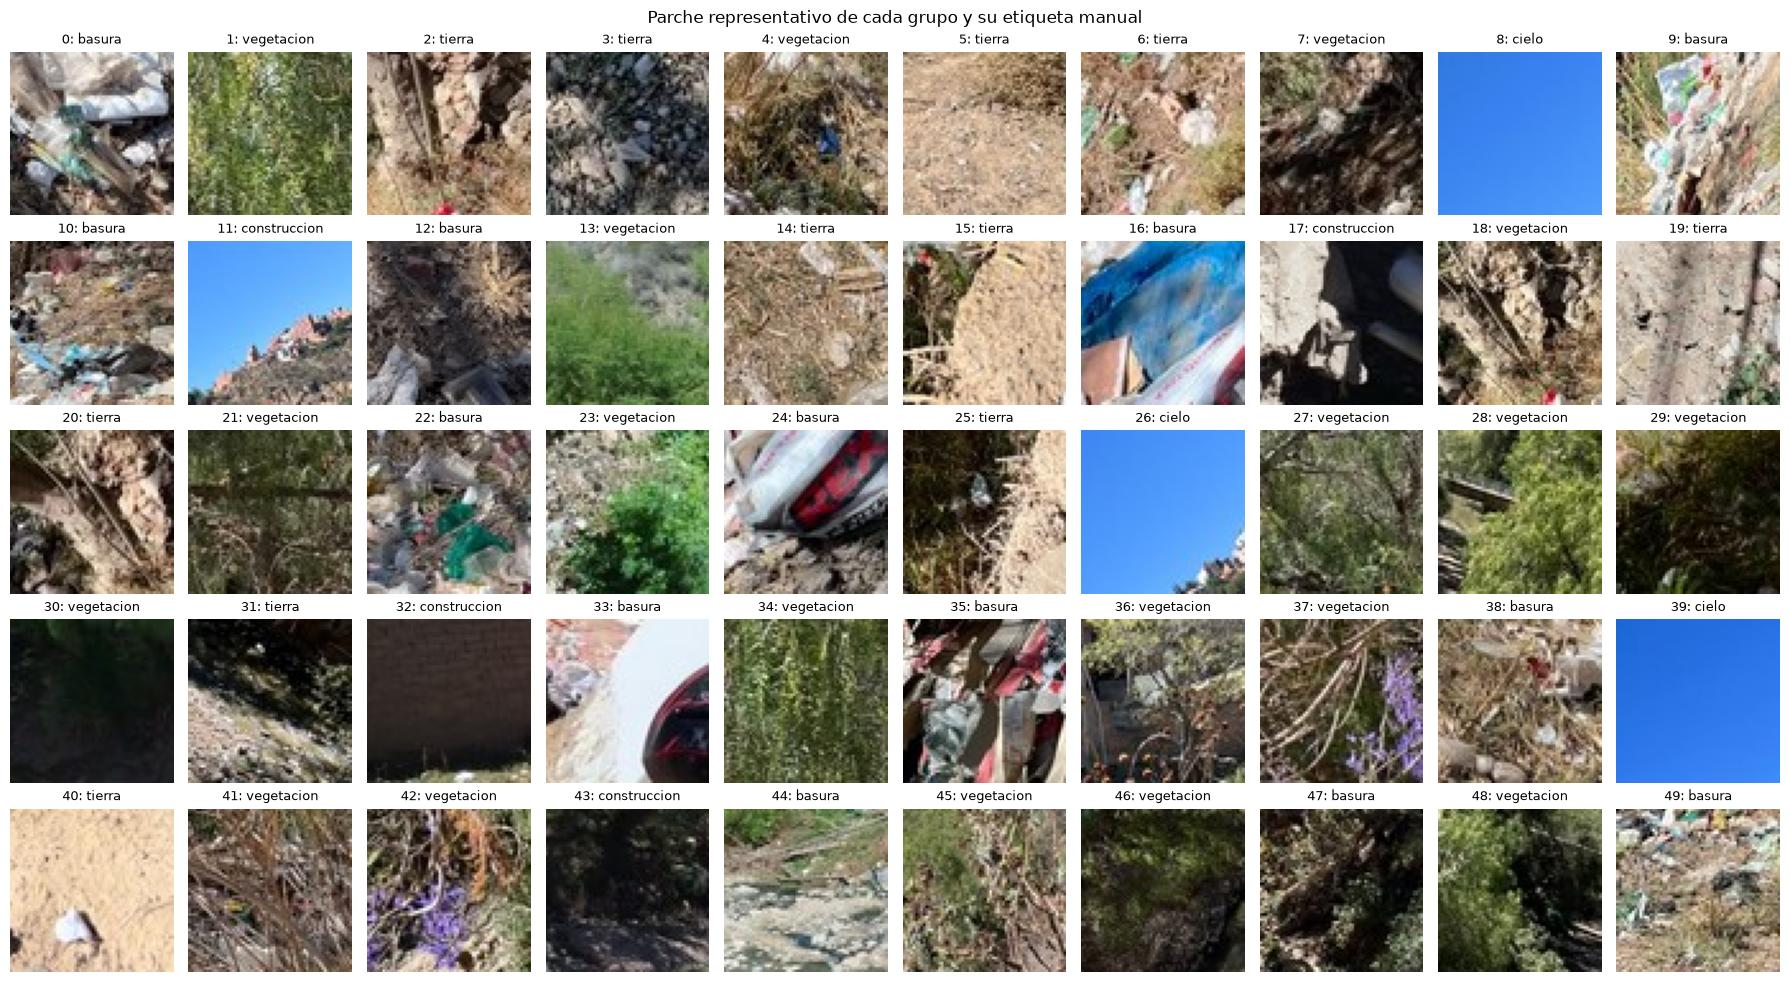

vegetacion      19
basura          13
tierra          11
construccion     4
cielo            3
Name: count, dtype: int64

In [11]:
ETIQUETAS_REPRESENTATIVOS = {
    0: 'basura', 1: 'vegetacion', 2: 'tierra', 3: 'tierra', 4: 'vegetacion',
    5: 'tierra', 6: 'tierra', 7: 'vegetacion', 8: 'cielo', 9: 'basura',
    10: 'basura', 11: 'construccion', 12: 'basura', 13: 'vegetacion', 14: 'tierra',
    15: 'tierra', 16: 'basura', 17: 'construccion', 18: 'vegetacion', 19: 'tierra',
    20: 'tierra', 21: 'vegetacion', 22: 'basura', 23: 'vegetacion', 24: 'basura',
    25: 'tierra', 26: 'cielo', 27: 'vegetacion', 28: 'vegetacion', 29: 'vegetacion',
    30: 'vegetacion', 31: 'tierra', 32: 'construccion', 33: 'basura', 34: 'vegetacion',
    35: 'basura', 36: 'vegetacion', 37: 'vegetacion', 38: 'basura', 39: 'cielo',
    40: 'tierra', 41: 'vegetacion', 42: 'vegetacion', 43: 'construccion', 44: 'basura',
    45: 'vegetacion', 46: 'vegetacion', 47: 'basura', 48: 'vegetacion', 49: 'basura',
}
CLASES = ['basura', 'vegetacion', 'tierra', 'cielo', 'construccion']

y_representativos = np.array([ETIQUETAS_REPRESENTATIVOS[k] for k in range(K)])

fig, axs = plt.subplots(5, 10, figsize=(18, 10))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(parches_train[idx_representativos[k]])
    ax.set_title(f'{k}: {y_representativos[k]}', fontsize=9)
    ax.axis('off')
plt.suptitle('Parche representativo de cada grupo y su etiqueta manual')
plt.tight_layout()
plt.show()

pd.Series(y_representativos).value_counts()

## 8. Propagación de etiquetas (aprendizaje semi-supervisado)

Igual que en el cuadernillo de clase:

- **Propagación total:** cada parche recibe la etiqueta del representativo de su grupo. Paso de 50 etiquetas a 912.
- **Propagación parcial:** solo se propaga al 20% de parches **más cercanos** a cada centroide. Los parches lejanos del centroide están en la "frontera" entre grupos y es más probable que tengan la etiqueta equivocada; descartarlos da etiquetas más limpias pero menos ejemplos.

In [12]:
y_propagada = y_representativos[kmeans.labels_]

PERCENTIL = 20
distancia_a_su_centroide = distancias[np.arange(len(X_train_esc)), kmeans.labels_]
cercanos = np.zeros(len(X_train_esc), dtype=bool)
for k in range(K):
    en_grupo = kmeans.labels_ == k
    limite = np.percentile(distancia_a_su_centroide[en_grupo], PERCENTIL)
    cercanos |= en_grupo & (distancia_a_su_centroide <= limite)

pd.DataFrame({
    'propagación total': pd.Series(y_propagada).value_counts(),
    f'propagación parcial ({PERCENTIL}%)': pd.Series(y_propagada[cercanos]).value_counts(),
}).reindex(CLASES)

,propagación total,propagación parcial (20%)
basura,307,66
vegetacion,352,79
tierra,230,53
cielo,7,3
construccion,16,4


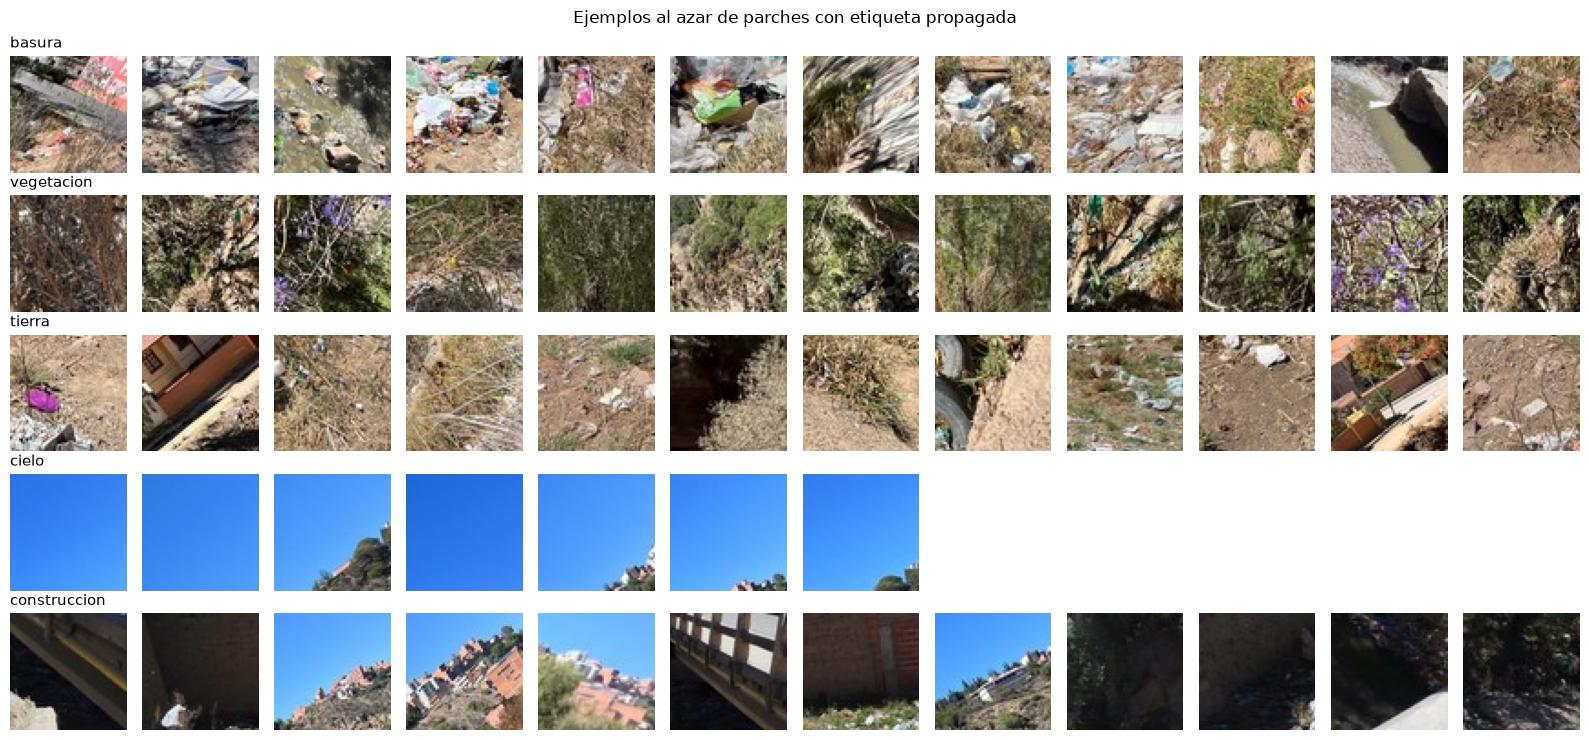

In [13]:
fig, axs = plt.subplots(len(CLASES), 12, figsize=(16, 7.5))
for fila, clase in enumerate(CLASES):
    ids = np.where(y_propagada == clase)[0]
    ids = np.random.choice(ids, min(12, len(ids)), replace=False)
    for col in range(12):
        ax = axs[fila, col]
        ax.axis('off')
        if col < len(ids):
            ax.imshow(parches_train[ids[col]])
    axs[fila, 0].set_title(clase, loc='left', fontsize=11)
plt.suptitle('Ejemplos al azar de parches con etiqueta propagada')
plt.tight_layout()
plt.show()

## 9. Etiquetas reales de prueba (verdad de referencia hecha a mano)

Para saber si el modelo de verdad funciona necesito compararlo con etiquetas **que no vengan de K-Means**. Por eso miré cada una de las 7 fotos de prueba con su cuadrícula de 64 x 64 y escribí la etiqueta de cada parche con una letra:

`B` = basura, `V` = vegetacion, `T` = tierra, `C` = cielo, `K` = construccion, `-` = no se usa (en `img_03` hay una persona en una esquina).

Cada texto es una **fila** de la cuadrícula de la foto, de izquierda a derecha.

In [14]:
LETRAS = {'B': 'basura', 'V': 'vegetacion', 'T': 'tierra', 'C': 'cielo', 'K': 'construccion'}

ETIQUETAS_PRUEBA = {
    'img_03.jpg': ['VKKKCCCC', 'VVVVVVVV', 'VVVKVVVV', 'VVVVVBBB', 'VBTTTBBT', 'BTTTTBT-'],
    'img_08.jpg': ['KKVVVV', 'VVVVVV', 'VVVVVT', 'VTTTBT', 'VBBBBB', 'VBBBBB', 'BBBBVV', 'BBTTVV'],
    'img_09.jpg': ['TBTBBB', 'TTBBBT', 'TTBBBB', 'TBBBTT', 'TTTBTB', 'TTBTTT', 'TBBTTB', 'TTTTBT'],
    'img_15.jpg': ['KKKV', 'KVVV', 'VVVV', 'BBVV', 'BBBB', 'BBBB', 'BBBB', 'BBBB'],
    'img_17.jpg': ['KVVV', 'VVVV', 'VVVV', 'BVVV', 'BBBB', 'BBBB', 'BBTB', 'BBBB'],
    'img_23.jpg': ['VVVV', 'VVVV', 'VVVV', 'VVVV', 'BTTT', 'BBTT', 'TTTT', 'BTTB'],
    'img_27.jpg': ['VVVVBB', 'VVVVBB', 'VVVBBT', 'VVBBBT', 'VVBBBT', 'VBBTTT', 'BBBTTT', 'BTTTTT'],
}

y_test = np.array([LETRAS.get(ETIQUETAS_PRUEBA[f.imagen][f.fila][f.columna]) for f in info_test.itertuples()])
validos = y_test != None
X_test_val, y_test_val = X_test[validos], y_test[validos].astype(str)

print('Parches de prueba etiquetados:', len(y_test_val))
pd.Series(y_test_val).value_counts().reindex(CLASES)

Parches de prueba etiquetados: 287


basura          103
vegetacion      100
tierra           69
cielo             4
construccion     11
Name: count, dtype: int64

## 10. Entrenamiento: regresión logística

Uso **regresión logística multiclase** (vista en clase en la unidad de clasificación). Va dentro de un `Pipeline` con `StandardScaler`, así el escalado se aprende solo con los datos con que se entrena cada modelo.

Comparo tres formas de entrenar, igual que en el cuadernillo de aprendizaje no supervisado de clase:
1. Solo con los **50 parches etiquetados a mano**.
2. Con **propagación total** (912 parches).
3. Con **propagación parcial** (20% más cercanos de cada grupo).

In [15]:
def nuevo_modelo():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEMILLA))


experimentos = {
    'Solo 50 representativos': (X_train[idx_representativos], y_representativos),
    'Propagación total': (X_train, y_propagada),
    f'Propagación parcial ({PERCENTIL}%)': (X_train[cercanos], y_propagada[cercanos]),
}

resultados = []
modelos = {}
for nombre, (X_e, y_e) in experimentos.items():
    modelo = nuevo_modelo().fit(X_e, y_e)
    pred = modelo.predict(X_test_val)
    modelos[nombre] = modelo
    resultados.append({'experimento': nombre, 'parches de entrenamiento': len(y_e),
                       'exactitud prueba': accuracy_score(y_test_val, pred),
                       'F1 macro prueba': f1_score(y_test_val, pred, average='macro')})

pd.DataFrame(resultados).set_index('experimento').round(3)

,parches de entrenamiento,exactitud prueba,F1 macro prueba
experimento,,,
Solo 50 representativos,50,0.690,0.554
Propagación total,912,0.683,0.550
Propagación parcial (20%),205,0.659,0.508


Los tres modelos quedan entre **0.66 y 0.69 de exactitud** con 5 clases. Lo importante es que con **solo 50 etiquetas humanas** (5% de los parches) ya se logra eso, gracias a K-Means: los representativos están justo en el centro de cada grupo, así que son ejemplos muy "típicos" de su clase. La propagación parcial sale un poco peor porque se queda con pocos ejemplos de cielo (3) y construcción (4).

Como modelo final elijo el de **propagación total**: usa todos los parches de entrenamiento, así que es el más estable (más datos = menos varianza) y el que mejor representa la variedad de las fotos. Esta decisión la tomo por el criterio del método, no por elegir el mejor número de la tabla de prueba (eso sería ajustar el modelo al conjunto de prueba).

## 11. Métricas del modelo final

Para decidir si el modelo es **válido** y qué tan **preciso** es reviso:

1. **Línea base:** qué exactitud tendría un modelo "tonto" que siempre dice la clase más común. El modelo tiene que superarla con claridad.
2. **Exactitud de entrenamiento vs prueba:** si entrenamiento fuera mucho más alta que prueba, habría sobreajuste.
3. **Precisión, recall y F1 por clase:** la exactitud sola esconde qué clases fallan.
4. **Matriz de confusión:** muestra con qué se confunde cada clase.
5. **Validación cruzada por fotos (GroupKFold):** repite el entrenamiento 5 veces dejando fuera fotos distintas, para ver si el resultado es estable.

In [16]:
modelo_final = modelos['Propagación total']
pred_test = modelo_final.predict(X_test_val)

base = DummyClassifier(strategy='most_frequent').fit(X_train, y_propagada)
exactitud_base = accuracy_score(y_test_val, base.predict(X_test_val))

exactitud_train = accuracy_score(y_propagada, modelo_final.predict(X_train))
exactitud_test = accuracy_score(y_test_val, pred_test)

print(f'Línea base (siempre "{base.predict(X_test_val[:1])[0]}"): {exactitud_base:.3f}')
print(f'Exactitud en entrenamiento (vs etiquetas propagadas): {exactitud_train:.3f}')
print(f'Exactitud en prueba (vs etiquetas manuales):          {exactitud_test:.3f}')
print(f'F1 macro en prueba:                                   {f1_score(y_test_val, pred_test, average="macro"):.3f}')

Línea base (siempre "vegetacion"): 0.348
Exactitud en entrenamiento (vs etiquetas propagadas): 0.877
Exactitud en prueba (vs etiquetas manuales):          0.683
F1 macro en prueba:                                   0.550


In [17]:
print(classification_report(y_test_val, pred_test, labels=CLASES, zero_division=0))

              precision    recall  f1-score   support

      basura       0.65      0.73      0.68       103
  vegetacion       0.78      0.83      0.80       100
      tierra       0.60      0.51      0.55        69
       cielo       0.67      0.50      0.57         4
construccion       0.33      0.09      0.14        11

    accuracy                           0.68       287
   macro avg       0.61      0.53      0.55       287
weighted avg       0.67      0.68      0.67       287



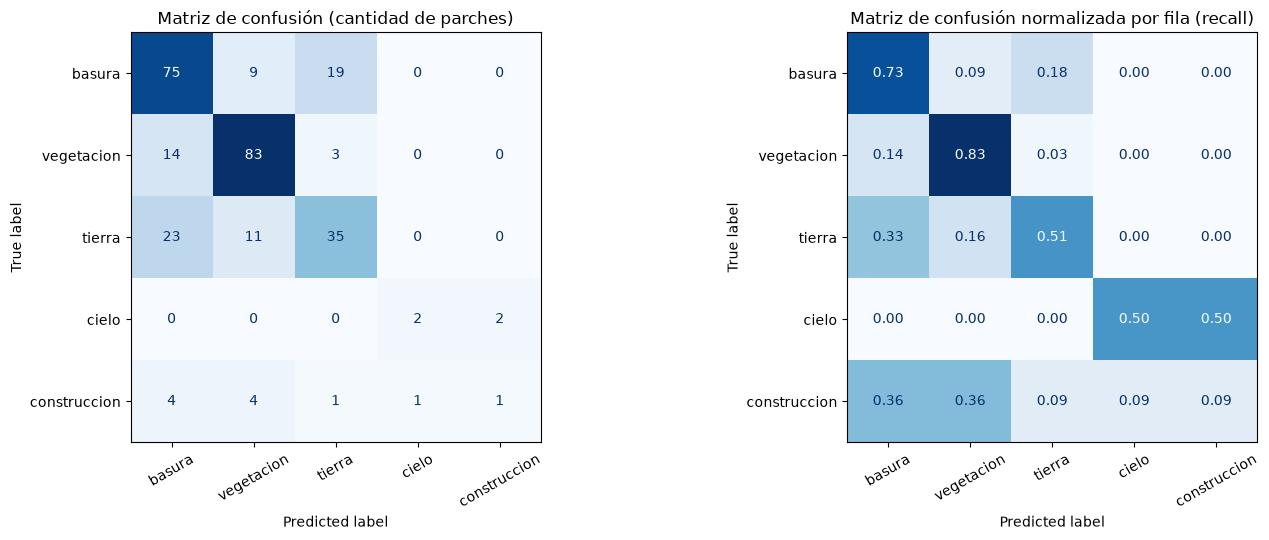

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test_val, pred_test, labels=CLASES, ax=axs[0],
                                        cmap='Blues', colorbar=False, xticks_rotation=30)
axs[0].set_title('Matriz de confusión (cantidad de parches)')
ConfusionMatrixDisplay.from_predictions(y_test_val, pred_test, labels=CLASES, ax=axs[1], normalize='true',
                                        cmap='Blues', colorbar=False, xticks_rotation=30, values_format='.2f')
axs[1].set_title('Matriz de confusión normalizada por fila (recall)')
plt.tight_layout()
plt.show()

In [19]:
grupos_train = info_train.imagen.values
validacion = GroupKFold(n_splits=5)
puntajes = cross_val_score(nuevo_modelo(), X_train, y_propagada, groups=grupos_train, cv=validacion, scoring='accuracy')

print('Exactitud en cada pliegue:', np.round(puntajes, 3))
print(f'Validación cruzada por fotos: {puntajes.mean():.3f} +/- {puntajes.std():.3f}')

Exactitud en cada pliegue: [0.79  0.865 0.833 0.776 0.725]
Validación cruzada por fotos: 0.798 +/- 0.048


### Interpretación de las métricas

- **El modelo es válido:** la exactitud en prueba (0.68) casi **duplica** la línea base (0.35), y se mide con fotos que el modelo nunca vio y con etiquetas hechas a mano, no con las de K-Means.
- **Sobreajuste moderado:** entrenamiento da 0.88 y la validación cruzada por fotos 0.80 (ambas comparadas contra las etiquetas propagadas). La diferencia de ~8 puntos es lo que el modelo "memoriza" de las fotos que ya vio; es moderada porque la regresión logística es un modelo simple (51 entradas).
- **Ruido de la propagación:** la validación cruzada (0.80) es más alta que la prueba (0.68) porque la primera se compara con etiquetas propagadas por K-Means y la segunda con mis etiquetas manuales. Esos ~12 puntos son, aproximadamente, el error que introduce asumir que todo un grupo tiene la misma etiqueta que su representativo.
- **Vegetación y basura** son las clases que mejor se reconocen (F1 alrededor de 0.7-0.8): la vegetación tiene un verde muy característico y la basura mezcla colores saturados con muchos bordes.
- **Tierra se confunde con basura:** en estas quebradas la basura está **tirada sobre la tierra**, así que muchos parches tienen las dos cosas; la frontera depende de "cuánta basura hay", lo cual es subjetivo incluso para una persona.
- **Cielo y construcción** tienen muy pocos ejemplos (cielo 4 y construcción 11 parches de prueba; en entrenamiento solo 7 y 16), por eso sus métricas son poco confiables. De los 4 parches de cielo, 2 se reconocen y los otros 2 se confunden con construcción, porque son parches que tienen cielo y casas a la vez. La construcción casi no se reconoce: los muros de ladrillo y las casas tienen colores parecidos a la tierra y a la basura.
- La validación cruzada varía de un pliegue a otro porque cada foto es distinta (luz, sombra, ángulo): por eso es importante separar por foto y no por parche.

## 12. Etiquetas dibujadas sobre las fotos de prueba

Cada parche se pinta con el color de su etiqueta: **rojo = basura**, **verde = vegetación**, **marrón = tierra**, **azul = cielo**, **gris = construcción**. A la izquierda la etiqueta real (manual) y a la derecha la del modelo.

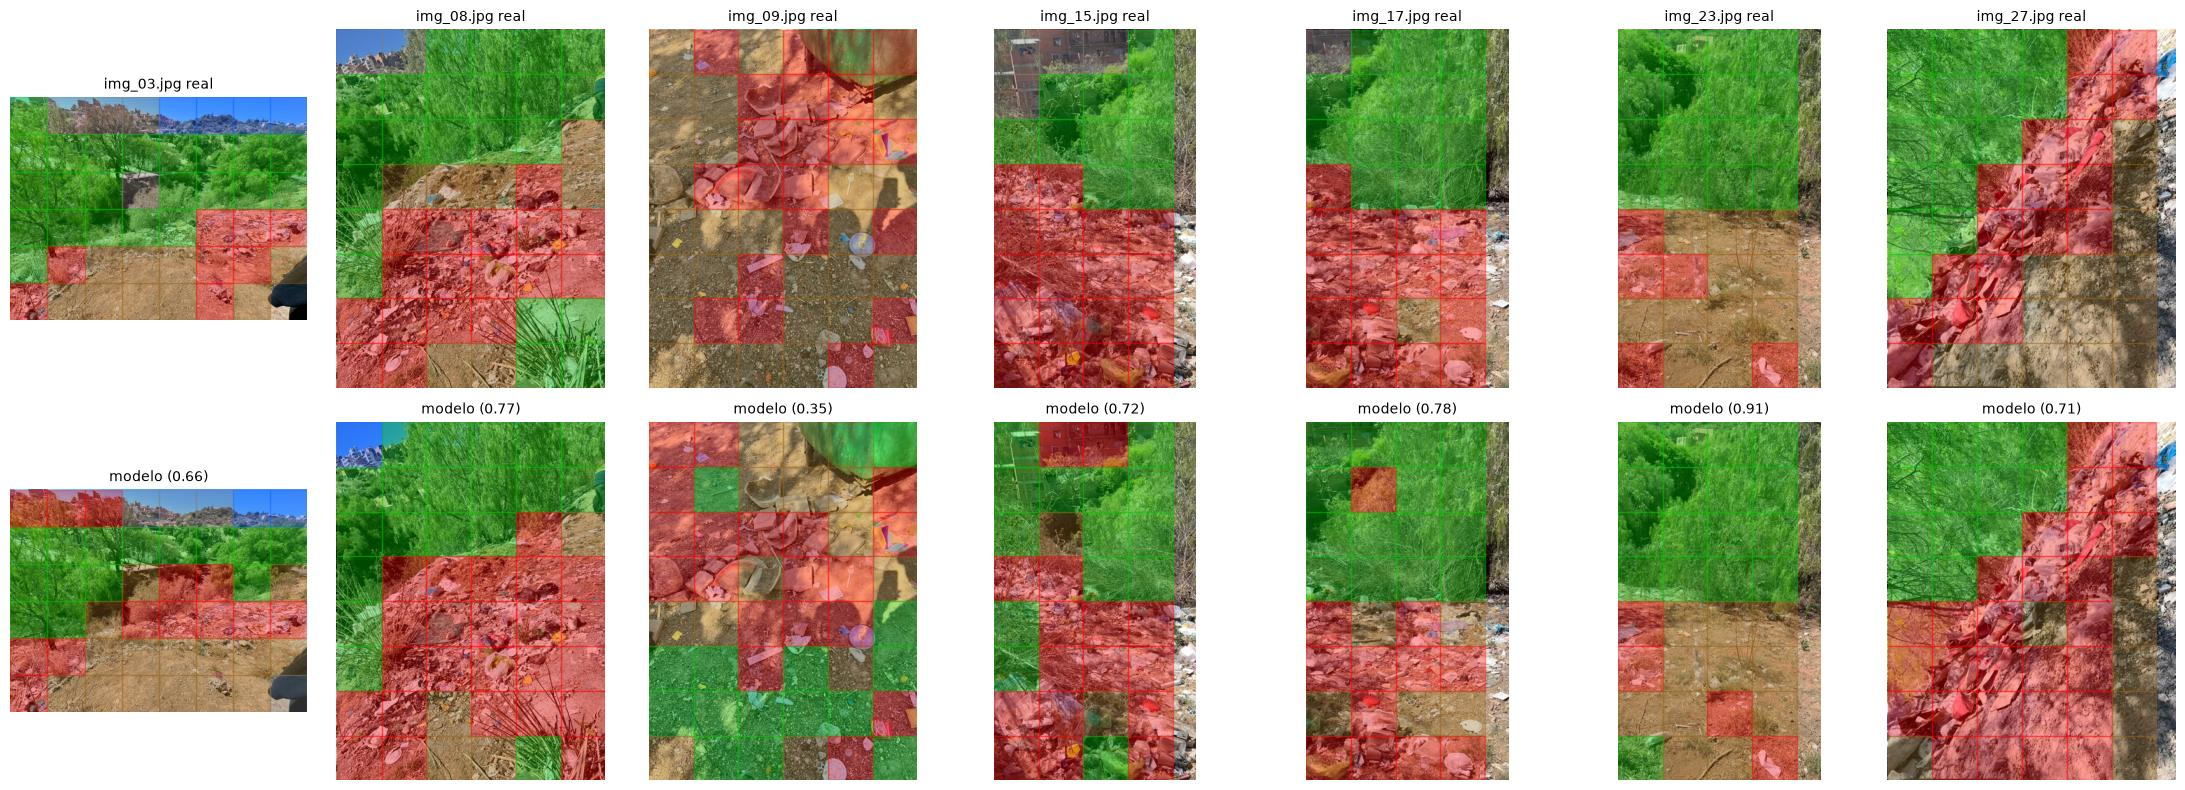

In [20]:
COLORES = {'basura': (1.0, 0.0, 0.0), 'vegetacion': (0.0, 0.8, 0.0), 'tierra': (0.6, 0.4, 0.1),
           'cielo': (0.1, 0.4, 1.0), 'construccion': (0.5, 0.5, 0.5)}


def mapa_de_etiquetas(imagen, posiciones, etiquetas, ax, titulo, tam=TAM_PARCHE):
    ax.imshow(imagen)
    for (fila, col), etiqueta in zip(posiciones, etiquetas):
        if etiqueta in COLORES:
            ax.add_patch(plt.Rectangle((col * tam, fila * tam), tam, tam, color=COLORES[etiqueta], alpha=0.35))
    ax.set_title(titulo, fontsize=10)
    ax.axis('off')


pred_todos_test = modelo_final.predict(X_test)
fig, axs = plt.subplots(2, len(IMAGENES_PRUEBA), figsize=(22, 8))
for j, nombre in enumerate(IMAGENES_PRUEBA):
    de_esta = (info_test.imagen == nombre).values
    posiciones = list(zip(info_test.fila[de_esta], info_test.columna[de_esta]))
    acierto = accuracy_score(y_test[de_esta & validos].astype(str), pred_todos_test[de_esta & validos])
    mapa_de_etiquetas(imagenes_ds1[nombre], posiciones, y_test[de_esta], axs[0, j], f'{nombre} real')
    mapa_de_etiquetas(imagenes_ds1[nombre], posiciones, pred_todos_test[de_esta], axs[1, j], f'modelo ({acierto:.2f})')
plt.tight_layout()
plt.show()

**Lectura:** en la mayoría de fotos el modelo acierta entre 66% y 91% de los parches y las zonas grandes (vegetación arriba, basura abajo) se reconocen bien. El caso más difícil es `img_09` (0.35): el **contenedor de basura verde** se confunde con vegetación porque el modelo solo ve colores y texturas, y el suelo con desechos pequeños queda en la frontera entre tierra y basura.

## 13. Probar el modelo con imágenes nuevas (ds2)

Las 8 fotos de ds2 son de otro estudiante, otro lugar y otra cámara. Ninguna se usó para entrenar. No tienen etiquetas, así que aquí la evaluación es **visual**: se dividen igual en parches de 64 x 64, se calculan las mismas 51 características, el modelo etiqueta cada parche y calculo qué porcentaje de la foto es cada clase. La **etiqueta principal de la foto** es la clase con más parches.

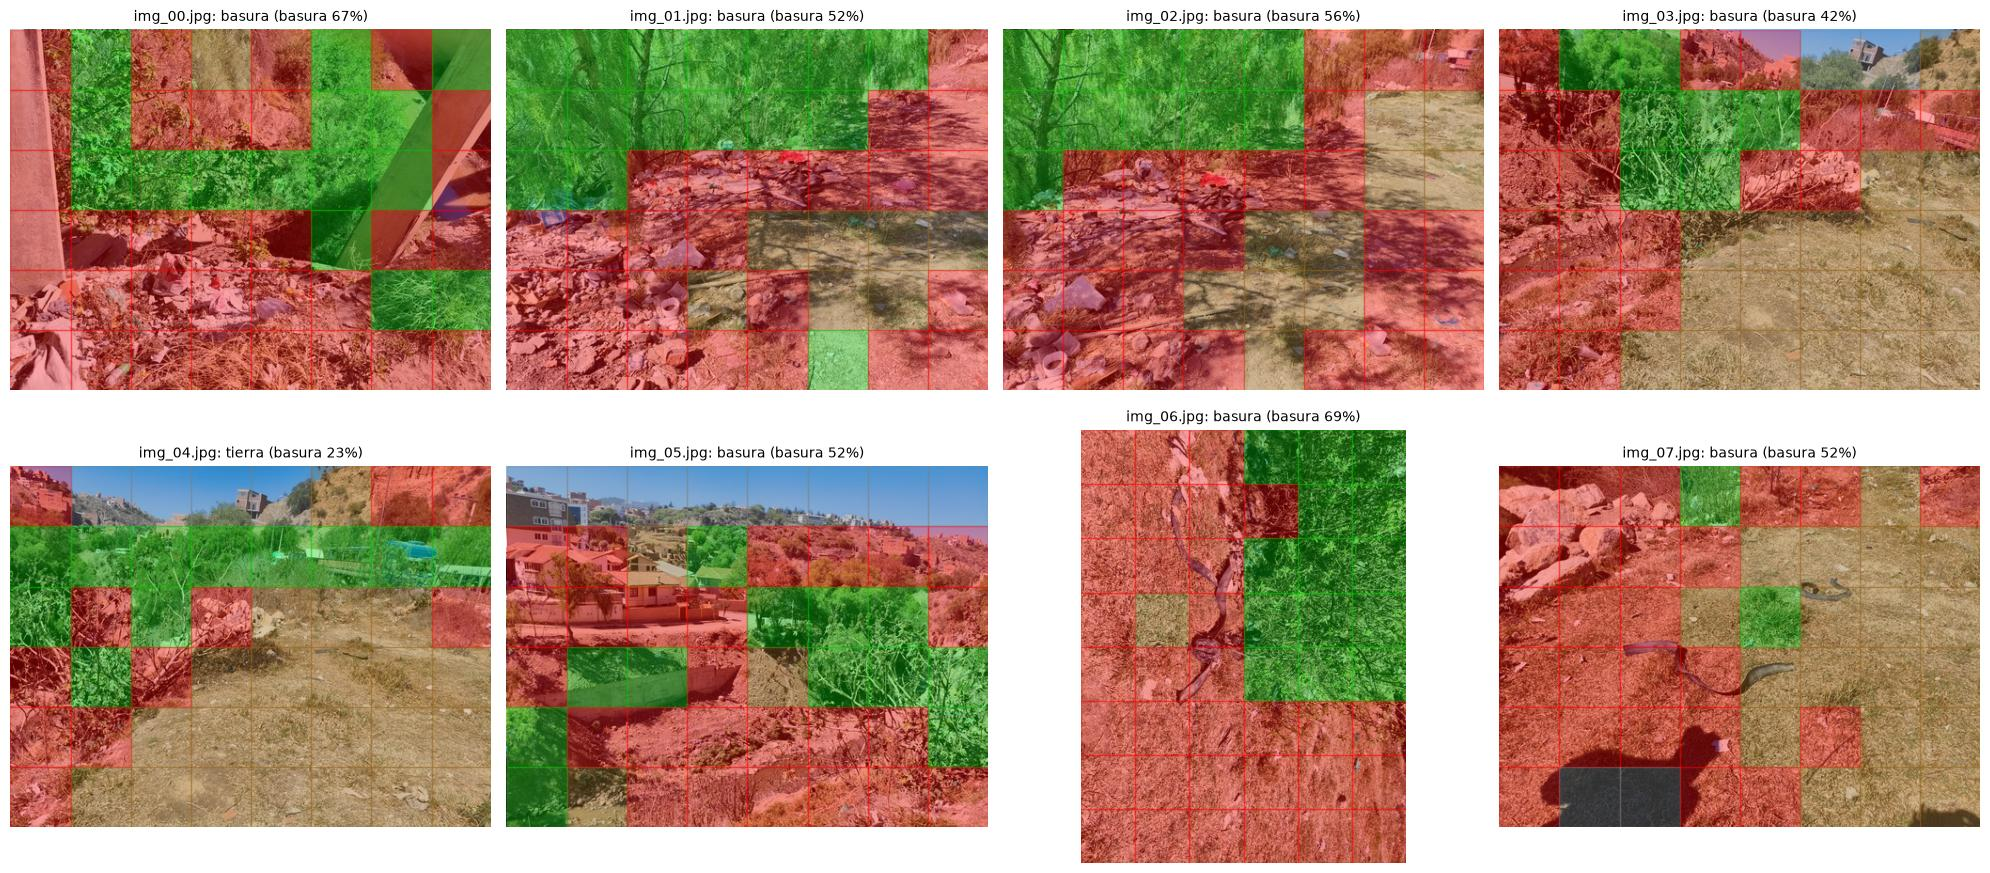

,basura,vegetacion,tierra,cielo,construccion,etiqueta principal
imagen,,,,,,
img_00.jpg,0.67,0.31,0.02,0.0,0.00,basura
img_01.jpg,0.52,0.33,0.15,0.0,0.00,basura
img_02.jpg,0.56,0.23,0.21,0.0,0.00,basura
img_03.jpg,0.42,0.15,0.40,0.0,0.04,basura
img_04.jpg,0.23,0.23,0.46,0.0,0.08,tierra
img_05.jpg,0.52,0.25,0.06,0.0,0.17,basura
img_06.jpg,0.69,0.29,0.02,0.0,0.00,basura
img_07.jpg,0.52,0.04,0.40,0.0,0.04,basura


In [21]:
nombres_ds2 = sorted(os.listdir(RUTA_DS2))
resumen_ds2 = []
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
for ax, nombre in zip(axs.ravel(), nombres_ds2):
    imagen = np.asarray(Image.open(os.path.join(RUTA_DS2, nombre)).convert('RGB'))
    ps, posiciones = dividir_en_parches(imagen)
    pred = modelo_final.predict(np.array([caracteristicas(p) for p in ps]))
    porcentajes = pd.Series(pred).value_counts(normalize=True).reindex(CLASES, fill_value=0)
    resumen_ds2.append({'imagen': nombre, **porcentajes.round(2).to_dict(), 'etiqueta principal': porcentajes.idxmax()})
    mapa_de_etiquetas(imagen, posiciones, pred, ax, f'{nombre}: {porcentajes.idxmax()} (basura {porcentajes.basura:.0%})')
plt.tight_layout()
plt.show()

pd.DataFrame(resumen_ds2).set_index('imagen')

**Lectura:** el modelo reconoce bien la vegetación verde, el cielo casi no aparece (las franjas de cielo de estas fotos miden menos de 64 px de alto) y la basura sí se detecta, pero **exagera la basura**: ramas secas, sombras y la tierra rojiza de estas fotos se marcan como basura. Esto se llama **cambio de dominio**: el modelo aprendió con fotos de una sola persona (otra cámara, otra hora, otro color de suelo). La forma de corregirlo sería agregar algunas fotos de ds2 al entrenamiento, que es justamente lo que sugiere el enunciado con "agregar más imágenes".

## 14. Guardar el modelo

Guardo en un solo archivo todo lo necesario para volver a usar el modelo sin reentrenar (igual que en el cuadernillo de clase de guardar y recuperar modelos): el escalador y el K-Means (la parte no supervisada), las etiquetas de los grupos y la regresión logística final.

In [22]:
os.makedirs('modelos', exist_ok=True)
paquete = {'escalador_kmeans': escalador, 'kmeans': kmeans, 'etiquetas_grupos': ETIQUETAS_REPRESENTATIVOS,
           'modelo': modelo_final, 'clases': CLASES, 'tam_parche': TAM_PARCHE}
with open('modelos/clasificador_parches.pkl', 'wb') as archivo:
    pickle.dump(paquete, archivo, protocol=pickle.HIGHEST_PROTOCOL)

with open('modelos/clasificador_parches.pkl', 'rb') as archivo:
    recuperado = pickle.load(archivo)
print('Modelo recuperado, exactitud en prueba:', round(accuracy_score(y_test_val, recuperado['modelo'].predict(X_test_val)), 3))

Modelo recuperado, exactitud en prueba: 0.683


## 15. Conclusiones (para la defensa)

**Qué se logró.** Un programa que toma fotos de quebradas, las divide en imágenes de 64 x 64 y pone a cada una la etiqueta de su objeto principal (`basura`, `vegetacion`, `tierra`, `cielo` o `construccion`), con una exactitud del **68%** en fotos nunca vistas, casi el doble de la línea base (35%).

**Por qué funciona con tan pocas etiquetas.** El paso clave es el **aprendizaje no supervisado**: K-Means organiza los 912 parches de entrenamiento en 50 grupos de parches parecidos. Como los grupos son pequeños, todos sus parches suelen ser del mismo tipo, y entonces basta con mirar **un parche por grupo** (50 en total) para etiquetar todo. Etiquetar a mano 912 parches habría costado 18 veces más trabajo.

**Por qué esas decisiones:**
- *Reducir a 512 px:* para que un parche de 64 px muestre un objeto y no un detalle; además el dataset pasa de varios MB a ~3 MB y se puede subir al repositorio.
- *Características de color y textura en vez de píxeles:* en fotos reales lo importante es **qué colores y bordes** hay, no **dónde** están dentro del parche.
- *Separar por foto:* evita la fuga de información y da una medida honesta.
- *Regresión logística:* es el modelo de clasificación más simple visto en clase, rápido de entrenar y fácil de interpretar; con solo 51 características y ~900 parches no hace falta algo más complejo.

**Limitaciones.** La frontera entre "tierra con un poco de basura" y "basura" es subjetiva; cielo y construcción tienen pocos ejemplos. Además, mis etiquetas manuales de prueba también pueden tener errores.

**Cómo se podría mejorar.** Usar más grupos (por ejemplo k = 100) y etiquetar más representativos, agregar fotos con más cielo y construcciones, o usar una red convolucional (como en el ejemplo de clase de PyTorch con imágenes de basura) si se tuviera GPU y más fotos.